# TP3 : Clustering et Word2Vec

Ce notebook présente deux analyses du corpus CAMille :
le regroupement des documents de 1910 à 1919 et l’exploration
des relations entre les mots avec Word2Vec.

## 1. Regroupement des documents d’une décennie

In [24]:
import os
import string
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import nltk
from nltk import word_tokenize
from nltk.corpus import stopwords
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer

### Choix de la décennie et des documents

In [25]:
current_dir = Path.cwd().resolve()
repo_root = next(
    (path for path in (current_dir, *current_dir.parents)
     if (path / ".git").exists()),
    current_dir,
)

data_path = repo_root / "data" / "txt"
decade = "1910"

if not data_path.is_dir():
    raise FileNotFoundError(f"Dossier introuvable : {data_path}")

files = sorted(
    file for file in data_path.glob("*.txt")
    if f"_{decade[:3]}" in file.name
)

print(f"Documents de {decade} à 1919 : {len(files)}")

Documents de 1910 à 1919 : 700


In [26]:
texts = [
    file.read_text(encoding="utf-8", errors="replace")
    for file in files
]

print(f"Documents chargés : {len(texts)}")
print(texts[0][:400])

Documents chargés : 700
V ’ ' ,^ïl\* I KTTWrMlftfTi¥riM»irniiÉiin*ii> i ri rr r r iuvur n>miriiirianiiiinnnw n irirm mriToi i -- — ~ - . #* * ■ * i* ■ ■■ • »■ ma nr WT e EXTRACTION COMPLETEMENT SANS DOULEUR g e H’&H*"Ge»s** SOUWEINE 155, fie Utft la. '- A1 « «i> ■■ 8 r - _ '' na, T' DEI9TS DEP. 5 FS. maison do oonfiahtà, INSTITUT DENTAIRE DU80HEH, G2, rue de Louynln . Surpassa tout co que roua avez pu voir en Belgique, v


## Vectorisation des textes avec TF-IDF

Transformer les textes en vecteurs numériques pour pouvoir les regrouper.

In [27]:
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

def preprocessing(text):
    text = text.translate(str.maketrans("", "", string.punctuation))
    return word_tokenize(text)

vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    token_pattern=None,
    stop_words=stopwords.words("french"),
    max_df=0.5,
    min_df=0.1,
    lowercase=True,
)

tfidf_vectors = vectorizer.fit_transform(texts)
print(f"Dimensions de la matrice TF-IDF : {tfidf_vectors.shape}")

Dimensions de la matrice TF-IDF : (700, 3878)


## Regroupement des documents avec K-means

Le modèle va répartir les documents en cinq groupes à partir de leurs vecteurs TF-IDF.

In [28]:
n_clusters = 5

km_model = KMeans(
    n_clusters=n_clusters,
    random_state=42,
    n_init=10,
)

clusters = km_model.fit_predict(tfidf_vectors)

for label in range(n_clusters):
    indices = np.where(clusters == label)[0]
    exemples = [files[i].name for i in indices[:3]]

    print(f"\nCluster {label} : {len(indices)} documents")
    print("Exemples :", ", ".join(exemples))


Cluster 0 : 108 documents
Exemples : KB_JB838_1910-01-22_01-00004.txt, KB_JB838_1910-02-09_01-00004.txt, KB_JB838_1910-03-05_01-00008.txt

Cluster 1 : 98 documents
Exemples : KB_JB838_1910-01-06_01-00008.txt, KB_JB838_1910-01-09_01-00010.txt, KB_JB838_1910-02-01_01-00007.txt

Cluster 2 : 303 documents
Exemples : KB_JB838_1910-01-07_01-00003.txt, KB_JB838_1910-01-17_01-00002.txt, KB_JB838_1910-01-22_01-00003.txt

Cluster 3 : 85 documents
Exemples : KB_JB838_1910-01-16_01-00009.txt, KB_JB838_1910-02-11_01-00006.txt, KB_JB838_1910-02-19_01-00006.txt

Cluster 4 : 106 documents
Exemples : KB_JB838_1910-01-13_01-00007.txt, KB_JB838_1910-02-10_01-00008.txt, KB_JB838_1910-02-17_11-00006.txt


### Mots fréquents dans chaque groupe

In [29]:
feature_names = vectorizer.get_feature_names_out()

for label in range(n_clusters):
    indices = np.where(clusters == label)[0]
    moyennes = np.asarray(tfidf_vectors[indices].mean(axis=0)).ravel()
    meilleurs_indices = moyennes.argsort()[::-1][:10]
    meilleurs_mots = [feature_names[i] for i in meilleurs_indices]

    print(f"Cluster {label} : {', '.join(meilleurs_mots)}")

Cluster 0 : notaire, contenant, cap, rentier, etude, ventes, louée, ord, ares, 500
Cluster 1 : vend, hp, ag, ecr, pianos, piano, occas, chêne, adr, mang
Cluster 2 : ministre, gouvernement, quo, président, question, allemands, belges, cela, soldats, projet
Cluster 3 : louer, ag, ecr, appart, jard, mod, garni, app, adr, ecrire
Cluster 4 : ecr, ag, référ, sach, fem, prés, serv, mén, réf, gag


In [30]:
for label in range(n_clusters):
    index = np.where(clusters == label)[0][0]

    print(f"\nCluster {label} — {files[index].name}")
    print(texts[index][:300].replace("\n", " "))


Cluster 0 — KB_JB838_1910-01-22_01-00004.txt
r,-/"> ^ ,FMO*L»A*MI -Si flScSSBafiSsiita iA-rr>. .c.*:j > .:tii^«mm- a /.«.j) ♦•kStP-i.’î.ï v . BULLETIN FINANCIER i:i'; ,f.': ' ■ Bruxelles, ,21 janvier. . ;. ;Vi Les: cours sont formes au lenno, où les va- •r r :J«lW: canadiennes,et surtout les. Mexico-T ram,, ■;. â'iiwcfivoaf eu hattsso .Mnôlble

Cluster 1 — KB_JB838_1910-01-06_01-00008.txt
V ’ ' ,^ïl\* I KTTWrMlftfTi¥riM»irniiÉiin*ii> i ri rr r r iuvur n>miriiirianiiiinnnw n irirm mriToi i -- — ~ - . #* * ■ * i* ■ ■■ • »■ ma nr WT e EXTRACTION COMPLETEMENT SANS DOULEUR g e H’&H*"Ge»s** SOUWEINE 155, fie Utft la. '- A1 « «i> ■■ 8 r - _ '' na, T' DEI9TS DEP. 5 FS. maison do oonfiahtà, I

Cluster 2 — KB_JB838_1910-01-07_01-00003.txt
Blousa Hakluyt Sdcfety, qui précisément ttanmialent & la collection mie possédait la Bibliothèque. On ne saurait trop attirer l’attention sur cette intéressante façon d’honorôr.la mémoire d’un parent qui a consacré parfois toute sa vie à établir et & rassemble

### Observation

Les mots fréquents suggèrent des groupes liés aux annonces, au commerce et à l’actualité. Cependant, les premiers fichiers examinés ne correspondent pas toujours aux mots dominants de leur groupe. Certains contiennent des sujets différents, et les erreurs d’OCR compliquent la lecture. Les clusters ne forment donc pas cinq thèmes clairement séparés ; leur interprétation reste approximative.

## Visualiser les groupes

La PCA projette les documents sur deux axes pour représenter leurs ressemblances dans un graphique.

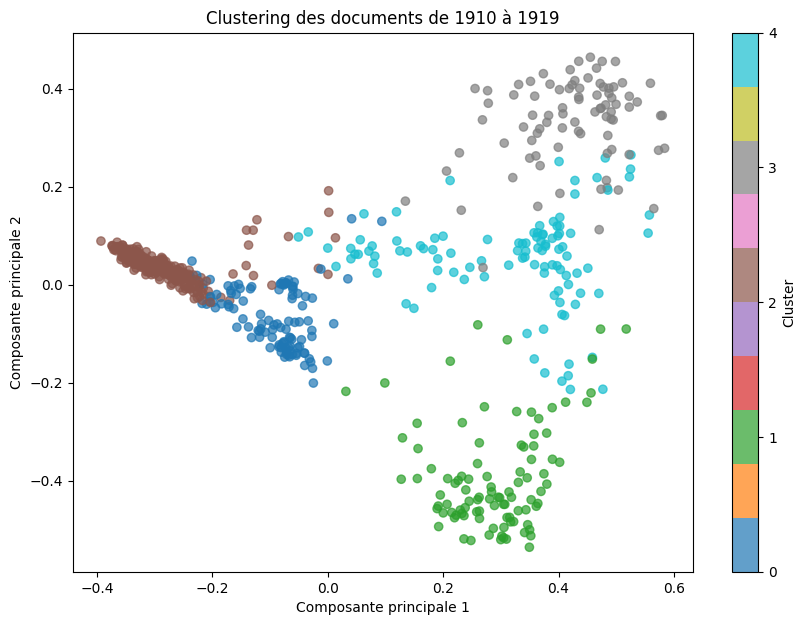

In [31]:
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(tfidf_vectors.toarray())

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    reduced_vectors[:, 0],
    reduced_vectors[:, 1],
    c=clusters,
    cmap="tab10",
    alpha=0.7,
)

plt.title("Clustering des documents de 1910 à 1919")
plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.colorbar(scatter, ticks=range(n_clusters), label="Cluster")
plt.show()

### Observation

Le graphique montre que certains groupes occupent des zones distinctes, notamment les clusters 1 et 3. Les clusters 0 et 2 sont proches, tandis que le cluster 4 est plus dispersé. La projection en deux dimensions facilite la visualisation, mais elle ne représente pas toutes les différences présentes dans les vecteurs TF-IDF.

## 4. Exploration des relations entre les mots avec Word2Vec

Comme Word2Vec apprend des représentations numériques à partir du contexte des mots,
le modèle sera entraîné sur les phrases du corpus.

In [34]:
from gensim.models import Word2Vec
from gensim.models.phrases import Phrases, Phraser
from nltk.tokenize import wordpunct_tokenize
from unidecode import unidecode

sentences_path = repo_root / "data" / "sents1.txt"

class MySentences:
    def __init__(self, filename):
        self.filename = filename

    def __iter__(self):
        with open(self.filename, encoding="utf-8", errors="replace") as file:
            for line in file:
               yield [
                        unidecode(word.lower())
                        for word in wordpunct_tokenize(line)
                        if word.isalpha() and len(word) > 1
                    ]

sentences = MySentences(sentences_path)
print(next(iter(sentences)))

['mi', 'imnri', 'hmu', 'tx', 'marche', 'tenu', 'hors', 'villa', 'la']


### Entraînement du modèle Word2Vec

Le modèle est entraîné sur les phrases du corpus. `window=5` définit le contexte pris autour de chaque mot ; `min_count=5` écarte les mots trop rares.

In [35]:
model = Word2Vec(
    sentences,
    vector_size=32,
    window=5,
    min_count=5,
    workers=4,
    epochs=5,
    seed=42,
)

print(f"Mots appris par le modèle : {len(model.wv)}")

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Mots appris par le modèle : 63692


In [36]:
termes = [
    "ministre", "gouvernement", "roi", "reine",
    "france", "allemagne", "bruxelles", "anvers",
]

for mot in termes:
    print(mot, mot in model.wv)

ministre True
gouvernement True
roi True
reine True
france True
allemagne True
bruxelles True
anvers True


### Comparaison des trois paires de mots

La similarité mesure à quel point deux mots apparaissent dans des contextes proches.

In [37]:
paires = [
    ("ministre", "gouvernement"),
    ("roi", "reine"),
    ("france", "allemagne"),
]

for mot1, mot2 in paires:
    score = model.wv.similarity(mot1, mot2)
    print(f"{mot1} / {mot2} : {score:.3f}")

ministre / gouvernement : 0.799
roi / reine : 0.645
france / allemagne : 0.901


### Recherche des mots proches de trois termes

In [38]:
for mot in ["ministre", "roi", "bruxelles"]:
    print(f"\nMots proches de « {mot} » :")
    for mot_proche, score in model.wv.most_similar(mot, topn=5):
        print(f"{mot_proche} : {score:.3f}")


Mots proches de « ministre » :
president : 0.854
ministere : 0.834
sultan : 0.823
chancelier : 0.800
gouvernement : 0.799

Mots proches de « roi » :
prince : 0.934
tsar : 0.881
pape : 0.832
empereur : 0.827
comte : 0.813

Mots proches de « bruxelles » :
luxembourg : 0.709
spa : 0.703
anvers : 0.697
ostende : 0.693
telephone : 0.667


### Observation

Les mots proches de « ministre » sont surtout des fonctions politiques. Ceux de
« roi » sont liés à la monarchie et à la noblesse. « Bruxelles » est rapproché
d’autres lieux belges, mais aussi de « telephone ». Les résultats reflètent les
contextes du corpus et peuvent être affectés par les erreurs d’OCR.